# Phase 02: Technical Application - Baseline Implementation

## Import Libraries

In [16]:
from pathlib import Path
import io, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay)
SEED = 42
DATA_PATH = Path('dly1875.csv')
OUT = Path('evidence'); OUT.mkdir(exist_ok=True)
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

Python: 3.13.16 | pandas: 2.2.3 | scikit-learn: 1.6.1


## Load and select dataset

In [17]:
# Find the CSV header
assert DATA_PATH.exists(), 'Upload dly1875.csv beside the notebook first.'
raw = DATA_PATH.read_bytes()
text = raw.decode('utf-8-sig')
lines = text.splitlines()
header = next(i for i, line in enumerate(lines) if line.lower().startswith('date,'))
cols = ['date','imaxdy','maxtp','imindy','mintp','igmin','gmin','irrd','rain','cbl','wdsp',
        'iffhm','hm','iddhm','ddhm','iffhg','hg','soil','pe','evap','smd_wd','smd_md','smd_pd','glorad']
assert lines[header].split(',') == ['date','ind','maxtp','ind','mintp','igmin','gmin','ind','rain','cbl','wdsp','ind','hm','ind','ddhm','ind','hg','soil','pe','evap','smd_wd','smd_md','smd_pd','glorad'], 'Unexpected schema: inspect the file.'

# Read numbers and dates
df = pd.read_csv(io.StringIO('\n'.join(lines[header:])), skipinitialspace=True)
df.columns = cols
for col in cols[1:]: df[col] = pd.to_numeric(df[col], errors='coerce')
df['date'] = pd.to_datetime(df['date'], format='%d-%b-%Y', errors='coerce')
assert df['date'].notna().all(), 'Unparsed dates need investigation.'

# Select 2018 to 2022
period = df.loc[df.date.between('2018-01-01','2022-12-31')].copy().sort_values('date')
assert not period.date.duplicated().any(), 'Duplicate dates require investigation.'
print('Station:', lines[0], '| original rows:', len(df), '| period rows:', len(period))
print('SHA256:', hashlib.sha256(raw).hexdigest())
display(period.head())
print('Rain indicators in selected period:'); display(period.irrd.value_counts(dropna=False).sort_index())


Station: Station Name: ATHENRY | original rows: 6061 | period rows: 1826
SHA256: b27fce32ea9ee1c3b6a351a6b1717ea30becbc44c21c05d53e349bde25258fb4


,date,imaxdy,maxtp,imindy,mintp,igmin,gmin,irrd,rain,cbl,...,ddhm,iffhg,hg,soil,pe,evap,smd_wd,smd_md,smd_pd,glorad
2866,2018-01-01,0,9.0,0,1.5,0.0,2.4,0,0.5,994.9,...,280.0,0,26,4.625,0.4,0.4,0.0,-0.1,-9.6,271.0
2867,2018-01-02,0,10.6,0,3.3,0.0,-2.0,0,13.8,989.9,...,220.0,0,46,5.487,0.8,1.0,0.0,-10.0,-10.0,77.0
2868,2018-01-03,0,8.8,0,5.2,0.0,3.9,0,6.9,987.9,...,260.0,0,45,5.654,0.8,1.0,0.0,-6.1,-10.0,144.0
2869,2018-01-04,0,11.0,0,2.7,0.0,4.3,0,6.7,983.5,...,290.0,0,34,5.672,0.2,0.3,0.0,-6.5,-10.0,223.0
2870,2018-01-05,0,8.1,0,-0.0,0.0,-3.5,0,2.6,989.1,...,240.0,0,23,3.760,0.3,0.4,0.0,-2.3,-10.0,159.0


Rain indicators in selected period:


,count
irrd,
0,1825
8,1


## Data cleaning and build predictors and target

In [18]:
# Clean quality flags
valid = period.irrd.eq(0) & period.rain.notna() & period.rain.ge(0)
clean = period.loc[valid].copy()
for value, flag in [('maxtp','imaxdy'),('mintp','imindy'),('gmin','igmin'),
                    ('hm','iffhm'),('ddhm','iddhm'),('hg','iffhg')]:
    accepted = [0,1] if value in ['maxtp','mintp','gmin'] else [0]
    clean.loc[~clean[flag].isin(accepted), value] = np.nan

# Choose the weather inputs
features = ['maxtp','mintp','gmin','cbl','wdsp','ddhm','hg','soil','pe','evap',
            'smd_wd','smd_md','smd_pd','glorad']
# Circular encoding puts 359 degrees near 1 degree.
a = np.deg2rad(clean['ddhm'])
clean['wind_sin'], clean['wind_cos'] = np.sin(a), np.cos(a)
features = [x for x in features if x != 'ddhm'] + ['wind_sin','wind_cos']

# Build X and y
X = clean[features].copy()
y = clean.rain.gt(0).astype(int)
assert 'rain' not in X.columns and 'hm' not in X.columns
assert y.nunique() == 2

print('Input shape:', X.shape)
print('Target shape:', y.shape)
display(X.head())

Input shape: (1825, 15)
Target shape: (1825,)


,maxtp,mintp,gmin,cbl,wdsp,hg,soil,pe,evap,smd_wd,smd_md,smd_pd,glorad,wind_sin,wind_cos
2866,9.0,1.5,2.4,994.9,7.6,26.0,4.625,0.4,0.4,0.0,-0.1,-9.6,271.0,-0.984808,0.173648
2867,10.6,3.3,-2.0,989.9,12.3,46.0,5.487,0.8,1.0,0.0,-10.0,-10.0,77.0,-0.642788,-0.766044
2868,8.8,5.2,3.9,987.9,13.9,45.0,5.654,0.8,1.0,0.0,-6.1,-10.0,144.0,-0.984808,-0.173648
2869,11.0,2.7,4.3,983.5,8.2,34.0,5.672,0.2,0.3,0.0,-6.5,-10.0,223.0,-0.939693,0.342020
2870,8.1,-0.0,-3.5,989.1,4.4,23.0,3.760,0.3,0.4,0.0,-2.3,-10.0,159.0,-0.866025,-0.500000


## Explore data and visualize distributions

Retained: 1825 | excluded: 1


,Missing predictors
maxtp,0
mintp,0
gmin,2
cbl,1
wdsp,1
hg,0
soil,1
pe,1
evap,1
smd_wd,1


,count,mean,std,min,25%,50%,75%,max
maxtp,1825.0,13.860877,4.970562,-1.500,10.300000,13.70000,17.40000,30.500
mintp,1825.0,6.164493,4.683910,-8.100,2.800000,6.20000,10.00000,18.000
gmin,1823.0,4.405156,5.688760,-11.800,0.200000,4.40000,8.90000,17.200
cbl,1824.0,1008.023410,12.345820,967.200,1000.075000,1009.30000,1016.70000,1040.900
wdsp,1824.0,7.088761,2.979646,1.200,4.900000,6.60000,8.80000,20.500
hg,1825.0,21.731507,8.071244,4.000,16.000000,21.00000,26.00000,56.000
soil,1824.0,11.355383,5.205340,-0.516,6.896500,11.19900,15.82800,24.855
pe,1824.0,1.452357,1.087199,0.000,0.600000,1.20000,2.20000,6.000
evap,1824.0,2.023958,1.503053,0.000,0.800000,1.60000,3.10000,7.600
smd_wd,1824.0,8.675110,14.283819,0.000,0.000000,1.00000,12.10000,79.700


Dry/rainy counts: {0: 509, 1: 1316}


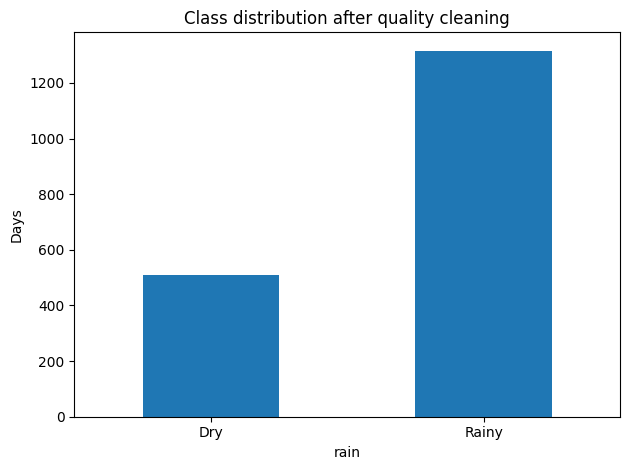

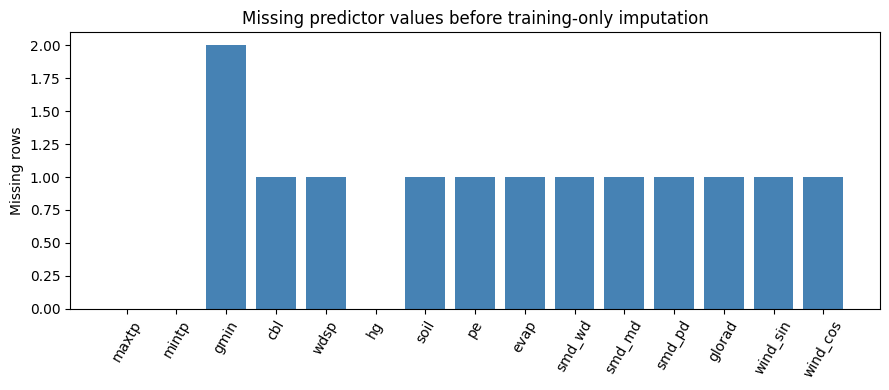

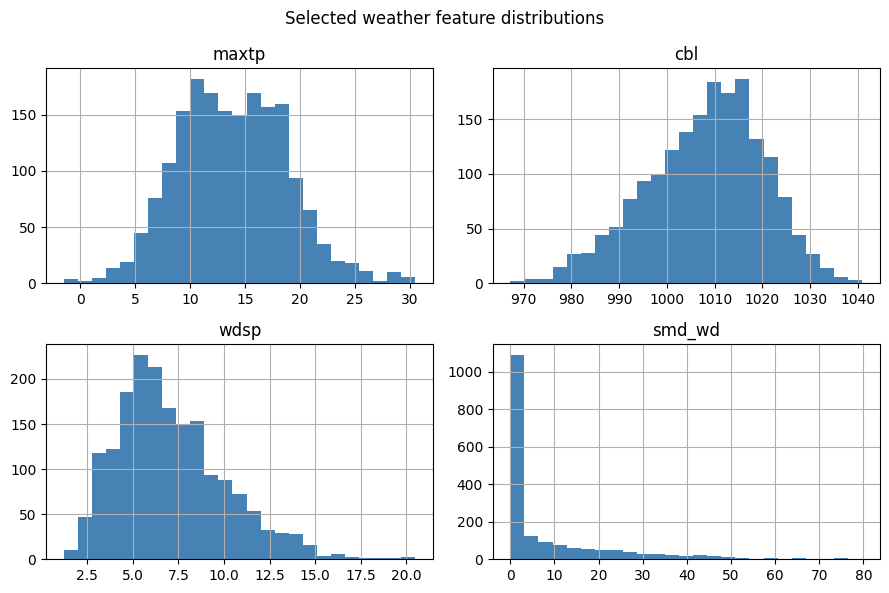

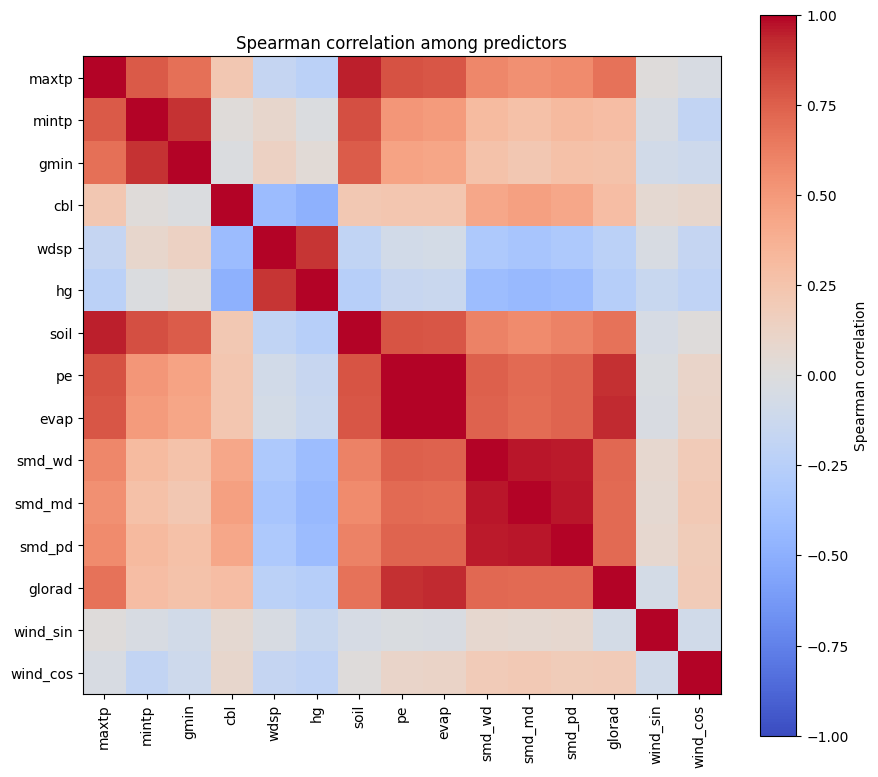

In [19]:
# Explore missing values and class balance
print('Retained:', len(clean), '| excluded:', len(period)-len(clean))
display(X.isna().sum().rename('Missing predictors').to_frame())
display(X.describe().T)
counts = y.value_counts().reindex([0,1], fill_value=0)
print('Dry/rainy counts:', counts.to_dict())
counts.rename(index={0:'Dry',1:'Rainy'}).plot.bar(rot=0, title='Class distribution after quality cleaning')
plt.ylabel('Days'); plt.tight_layout(); plt.savefig(OUT/'class_distribution.png', dpi=140); plt.show()

# Data visualizations
fig, ax = plt.subplots(figsize=(9,4))
missing = X.isna().sum()
ax.bar(missing.index, missing.values, color='steelblue')
ax.set_title('Missing predictor values before training-only imputation')
ax.set_ylabel('Missing rows'); ax.tick_params(axis='x',rotation=60)
plt.tight_layout(); plt.savefig(OUT/'missing_values.png',dpi=140); plt.show()

X[['maxtp','cbl','wdsp','smd_wd']].hist(bins=25,figsize=(9,6),color='steelblue')
plt.suptitle('Selected weather feature distributions')
plt.tight_layout(); plt.savefig(OUT/'feature_histograms.png',dpi=140); plt.show()

corr = X.corr(method='spearman')
fig, ax = plt.subplots(figsize=(9,8))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr)),corr.columns,rotation=90)
ax.set_yticks(range(len(corr)),corr.columns)
ax.set_title('Spearman correlation among predictors')
fig.colorbar(im,ax=ax,label='Spearman correlation')
plt.tight_layout(); plt.savefig(OUT/'correlation_heatmap.png',dpi=140); plt.show()


## Split data and establish the benchmark

In [20]:
# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
assert X_train.notna().any().all()
print('Training rows:',len(X_train))
print('Test rows:',len(X_test))

# Train a simple majority benchmark
dummy_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])
dummy_model.fit(X_train, y_train)
dummy_predictions = dummy_model.predict(X_test)
print('Dummy accuracy:', accuracy_score(y_test, dummy_predictions))
print('Dummy balanced accuracy:', balanced_accuracy_score(y_test, dummy_predictions))


Training rows: 1460
Test rows: 365
Dummy accuracy: 0.7205479452054795
Dummy balanced accuracy: 0.5


## Create and train Logistic Regression

In [21]:
# Create the Logistic Regression pipeline
lr_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', PowerTransformer(method='yeo-johnson')),
    ('classifier', LogisticRegression(C=1.0, max_iter=2000, random_state=SEED))
])
print(lr_model)

# Train Logistic Regression
lr_model.fit(X_train, y_train)
print('Logistic Regression training completed.')

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', PowerTransformer()),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])
Logistic Regression training completed.


## Predict and evaluate Logistic Regression

,Actual,Predicted,Rain probability
3392,0,1,0.696577
4190,0,1,0.589499
2914,1,1,0.947441
2965,1,1,0.767148
3945,1,1,0.982389
2877,1,1,0.975616
4371,1,1,0.963981
3504,1,1,0.933698
4478,1,0,0.151453
3389,1,1,0.955376


,Logistic Regression
Accuracy,0.8164
Precision,0.8858
Sensitivity,0.8555
Specificity,0.7157
F1,0.8704
Balanced accuracy,0.7856
ROC-AUC,0.8927
Average precision,0.9582


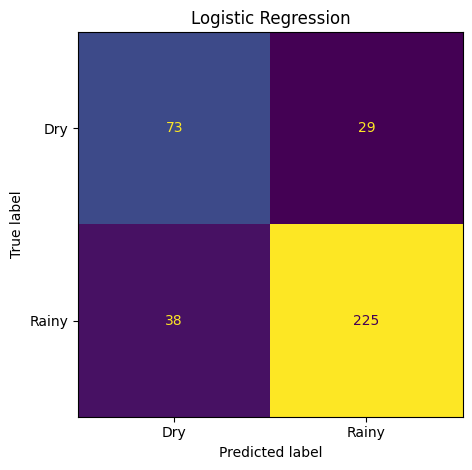

In [22]:
# Predict with Logistic Regression
lr_predictions = lr_model.predict(X_test)
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]
display(pd.DataFrame({'Actual':y_test, 'Predicted':lr_predictions,
                      'Rain probability':lr_probabilities}).head(10))

# Calculate Logistic Regression metrics
lr_matrix = confusion_matrix(y_test, lr_predictions, labels=[0,1])
tn, fp, fn, tp = lr_matrix.ravel()
lr_metrics = {
    'Accuracy': accuracy_score(y_test, lr_predictions),
    'Precision': precision_score(y_test, lr_predictions, zero_division=0),
    'Sensitivity': recall_score(y_test, lr_predictions, zero_division=0),
    'Specificity': tn / (tn + fp),
    'F1': f1_score(y_test, lr_predictions, zero_division=0),
    'Balanced accuracy': balanced_accuracy_score(y_test, lr_predictions),
    'ROC-AUC': roc_auc_score(y_test, lr_probabilities),
    'Average precision': average_precision_score(y_test, lr_probabilities)
}
display(pd.Series(lr_metrics, name='Logistic Regression').round(4))

# Plot the Logistic Regression confusion matrix
ConfusionMatrixDisplay(lr_matrix, display_labels=['Dry','Rainy']).plot(colorbar=False)
plt.title('Logistic Regression')
plt.tight_layout()
plt.savefig(OUT / 'lr_confusion_matrix.png', dpi=140)
plt.show()


## Create and train Random Forest

In [23]:
# Create the Random Forest pipeline
rf_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                          random_state=SEED, n_jobs=1))
])
print(rf_model)

# Train Random Forest
rf_model.fit(X_train, y_train)
print('Random Forest training completed.')

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 RandomForestClassifier(min_samples_leaf=2, n_estimators=200,
                                        n_jobs=1, random_state=42))])
Random Forest training completed.


## Predict and evaluate Random Forest

,Actual,Predicted,Rain probability
3392,0,1,0.675929
4190,0,1,0.631333
2914,1,1,1.000000
2965,1,1,0.662917
3945,1,1,0.998333
2877,1,1,1.000000
4371,1,1,1.000000
3504,1,1,0.887202
4478,1,0,0.138512
3389,1,1,0.772988


,Random Forest
Accuracy,0.8356
Precision,0.8859
Sensitivity,0.8859
Specificity,0.7059
F1,0.8859
Balanced accuracy,0.7959
ROC-AUC,0.9094
Average precision,0.9659


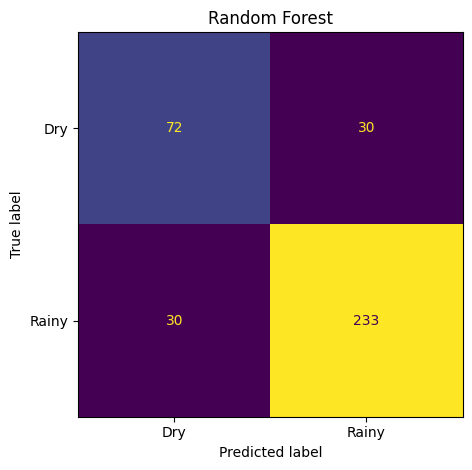

In [24]:
# Predict with Random Forest
rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]
display(pd.DataFrame({'Actual':y_test,'Predicted':rf_predictions,
                      'Rain probability':rf_probabilities}).head(10))

# Calculate Random Forest metrics
rf_matrix = confusion_matrix(y_test, rf_predictions, labels=[0,1])
tn, fp, fn, tp = rf_matrix.ravel()
rf_metrics = {
    'Accuracy': accuracy_score(y_test, rf_predictions),
    'Precision': precision_score(y_test, rf_predictions, zero_division=0),
    'Sensitivity': recall_score(y_test, rf_predictions, zero_division=0),
    'Specificity': tn / (tn + fp),
    'F1': f1_score(y_test, rf_predictions, zero_division=0),
    'Balanced accuracy': balanced_accuracy_score(y_test, rf_predictions),
    'ROC-AUC': roc_auc_score(y_test, rf_probabilities),
    'Average precision': average_precision_score(y_test, rf_probabilities)
}
display(pd.Series(rf_metrics, name='Random Forest').round(4))

# Plot the Random Forest confusion matrix
ConfusionMatrixDisplay(rf_matrix, display_labels=['Dry','Rainy']).plot(colorbar=False)
plt.title('Random Forest')
plt.tight_layout()
plt.savefig(OUT / 'rf_confusion_matrix.png', dpi=140)
plt.show()


## Tune Logistic Regression and visualize validation

,param_classifier__C,mean_train_score,mean_test_score,std_test_score
0,0.1,0.787031,0.780385,0.030757
1,1.0,0.788484,0.790441,0.023876
2,10.0,0.787395,0.788366,0.020409


Selected setting: {'classifier__C': 1.0}
Best mean validation score: 0.790440631691354


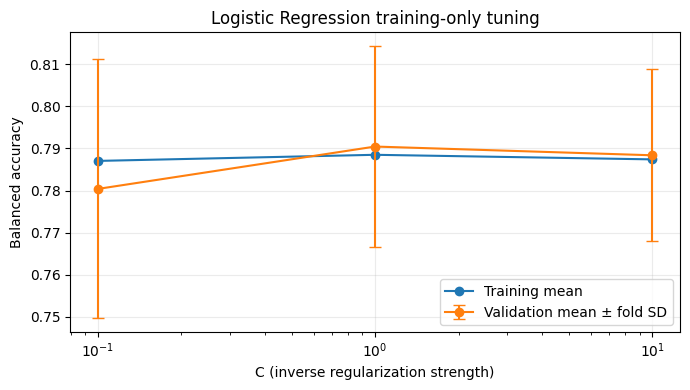

In [25]:
# Configure Logistic Regression tuning
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
parameter_grid = {'classifier__C':[0.1,1.0,10.0]}
lr_search = GridSearchCV(lr_model, parameter_grid, scoring='balanced_accuracy',
                         cv=cv, n_jobs=1, return_train_score=True)

# Run tuning using training data
lr_search.fit(X_train, y_train)
tuning_results = pd.DataFrame(lr_search.cv_results_)[
    ['param_classifier__C','mean_train_score','mean_test_score','std_test_score']]
display(tuning_results)
print('Selected setting:',lr_search.best_params_)
print('Best mean validation score:',lr_search.best_score_)
tuned_lr_model = lr_search.best_estimator_

# Tuning visualization
fig, ax = plt.subplots(figsize=(7,4))
c_values = tuning_results['param_classifier__C'].astype(float)
ax.plot(c_values,tuning_results['mean_train_score'],'o-',label='Training mean')
ax.errorbar(c_values,tuning_results['mean_test_score'],
            yerr=tuning_results['std_test_score'],fmt='o-',capsize=4,label='Validation mean ± fold SD')
ax.set_xscale('log');ax.set_xlabel('C (inverse regularization strength)')
ax.set_ylabel('Balanced accuracy');ax.set_title('Logistic Regression training-only tuning')
ax.legend();ax.grid(alpha=0.25)
plt.tight_layout();plt.savefig(OUT/'tuning_curve.png',dpi=140);plt.show()


## Evaluate tuned Logistic Regression

,Tuned Logistic Regression
Accuracy,0.8164
Precision,0.8858
Sensitivity,0.8555
Specificity,0.7157
F1,0.8704
Balanced accuracy,0.7856
ROC-AUC,0.8927
Average precision,0.9582


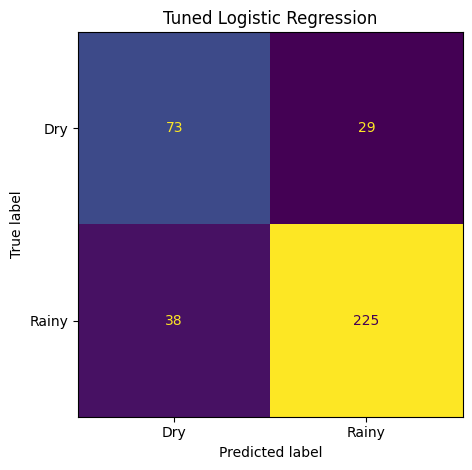

In [26]:
# Predict with tuned Logistic Regression
tuned_predictions = tuned_lr_model.predict(X_test)
tuned_probabilities = tuned_lr_model.predict_proba(X_test)[:,1]

# Evaluate tuned Logistic Regression
tuned_matrix = confusion_matrix(y_test, tuned_predictions, labels=[0,1])
tn, fp, fn, tp = tuned_matrix.ravel()
tuned_metrics = {
    'Accuracy': accuracy_score(y_test, tuned_predictions),
    'Precision': precision_score(y_test, tuned_predictions, zero_division=0),
    'Sensitivity': recall_score(y_test, tuned_predictions, zero_division=0),
    'Specificity': tn / (tn + fp),
    'F1': f1_score(y_test, tuned_predictions, zero_division=0),
    'Balanced accuracy': balanced_accuracy_score(y_test, tuned_predictions),
    'ROC-AUC': roc_auc_score(y_test, tuned_probabilities),
    'Average precision': average_precision_score(y_test, tuned_probabilities)
}
display(pd.Series(tuned_metrics, name='Tuned Logistic Regression').round(4))
ConfusionMatrixDisplay(tuned_matrix, display_labels=['Dry','Rainy']).plot(colorbar=False)
plt.title('Tuned Logistic Regression')
plt.tight_layout()
plt.savefig(OUT / 'tuned_confusion_matrix.png', dpi=140)
plt.show()


## Compare models and plot ROC and PR curves

,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced accuracy,ROC-AUC,Average precision
Logistic Regression,0.8164,0.8858,0.8555,0.7157,0.8704,0.7856,0.8927,0.9582
Random Forest,0.8356,0.8859,0.8859,0.7059,0.8859,0.7959,0.9094,0.9659
Tuned Logistic Regression,0.8164,0.8858,0.8555,0.7157,0.8704,0.7856,0.8927,0.9582


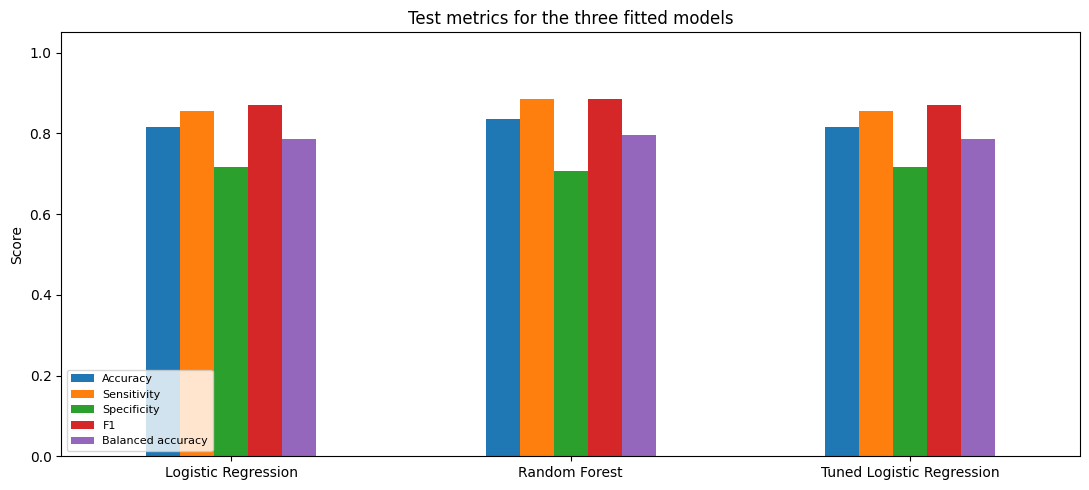

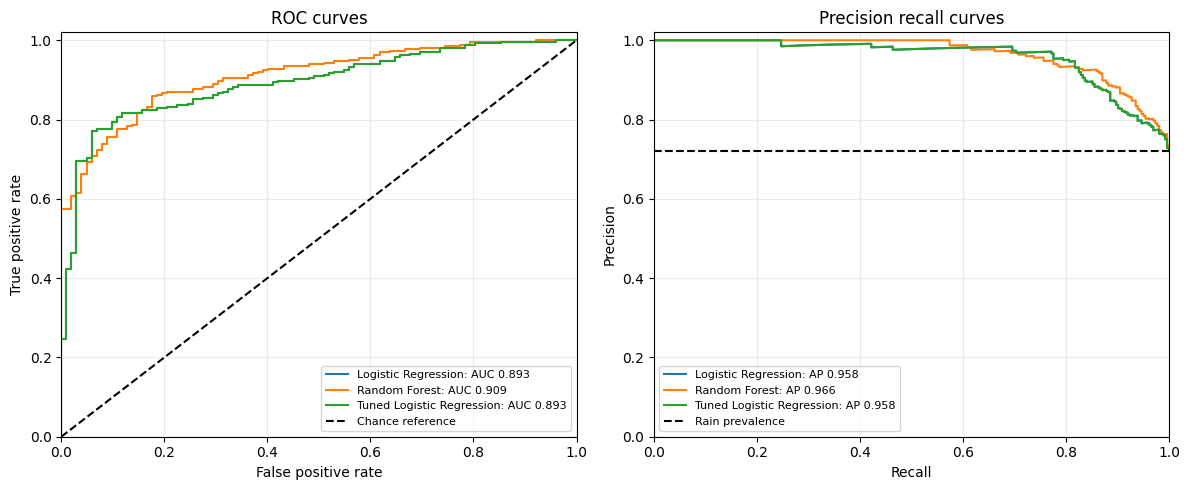

In [27]:
# Compare your measured results
results = pd.DataFrame([lr_metrics, rf_metrics, tuned_metrics],
    index=['Logistic Regression','Random Forest','Tuned Logistic Regression'])
display(results.round(4))
results.to_csv(OUT/'test_results.csv')
tuning_results.to_csv(OUT/'tuning_results.csv',index=False)

# Model metric comparison
selected = results[['Accuracy','Sensitivity','Specificity','F1','Balanced accuracy']]
ax = selected.plot.bar(figsize=(11,5),ylim=(0,1.05),rot=0)
ax.set_title('Test metrics for the three fitted models');ax.set_ylabel('Score')
ax.legend(loc='lower left',fontsize=8)
plt.tight_layout();plt.savefig(OUT/'model_metric_comparison.png',dpi=140);plt.show()

# ROC and precision recall curves
from sklearn.metrics import roc_curve, precision_recall_curve
probability_sets = {'Logistic Regression':lr_probabilities,
                    'Random Forest':rf_probabilities,
                    'Tuned Logistic Regression':tuned_probabilities}
fig, axes = plt.subplots(1,2,figsize=(12,5))
for name, probabilities in probability_sets.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    axes[0].plot(fpr,tpr,label=f'{name}: AUC {roc_auc_score(y_test,probabilities):.3f}')
    axes[1].plot(recall,precision,label=f'{name}: AP {average_precision_score(y_test,probabilities):.3f}')
axes[0].plot([0,1],[0,1],'k--',label='Chance reference')
axes[1].axhline(y_test.mean(),color='black',linestyle='--',label='Rain prevalence')
for ax in axes:
    ax.set_xlim(0,1);ax.set_ylim(0,1.02);ax.grid(alpha=0.25);ax.legend(fontsize=8)
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC curves')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision recall curves')
plt.tight_layout();plt.savefig(OUT/'roc_pr_curves.png',dpi=140);plt.show()

## Compare with the paper and check later-year performance

In [28]:
# Compare with published Table 2
published = pd.DataFrame({'Sensitivity':[0.956,1.0,1.0],
    'Specificity':[1.0,1.0,1.0], 'Balanced accuracy':[0.978,1.0,1.0]},
    index=['Logistic Regression','Random Forest','XGBoost'])
display(published)
comparison = results.loc[['Logistic Regression','Random Forest'],
    ['Sensitivity','Specificity','Balanced accuracy']].join(published.add_prefix('Paper '))
comparison['Difference in balanced accuracy (percentage points)'] = 100*(
    comparison['Balanced accuracy']-comparison['Paper Balanced accuracy'])
display(comparison.round(4))
comparison.to_csv(OUT/'paper_comparison.csv')

# Create a separate chronological experiment
earlier = clean.date.lt('2022-01-01')
later = ~earlier
assert clean.loc[earlier,'date'].max() < clean.loc[later,'date'].min()
assert y[earlier].nunique()==2 and y[later].nunique()==2
time_model = Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',PowerTransformer(method='yeo-johnson')),
    ('classifier',LogisticRegression(C=1.0,max_iter=2000,random_state=SEED))
])
time_model.fit(X[earlier],y[earlier])
time_predictions = time_model.predict(X[later])
print('Earlier training rows:',int(earlier.sum()),'| 2022 test rows:',int(later.sum()))
print('2022 accuracy:',accuracy_score(y[later],time_predictions))
print('2022 balanced accuracy:',balanced_accuracy_score(y[later],time_predictions))

# Evidence based findings
print(f'Majority benchmark: accuracy {accuracy_score(y_test,dummy_predictions):.2%}; balanced accuracy {balanced_accuracy_score(y_test,dummy_predictions):.2%}.')
for name, row in results.iterrows():
    print(f'{name}: balanced accuracy {row["Balanced accuracy"]:.2%}; rainy-day recall {row["Sensitivity"]:.2%}; dry-day recall {row["Specificity"]:.2%}.')
print('Best training-CV C:',lr_search.best_params_['classifier__C'])
print('Published score differences are descriptive, not proof that the paper is wrong.')
print('Compare preprocessing, features, quality policy and splitting before interpreting score differences.')

,Sensitivity,Specificity,Balanced accuracy
Logistic Regression,0.956,1.0,0.978
Random Forest,1.000,1.0,1.000
XGBoost,1.000,1.0,1.000


,Sensitivity,Specificity,Balanced accuracy,Paper Sensitivity,Paper Specificity,Paper Balanced accuracy,Difference in balanced accuracy (percentage points)
Logistic Regression,0.8555,0.7157,0.7856,0.956,1.0,0.978,-19.2400
Random Forest,0.8859,0.7059,0.7959,1.000,1.0,1.000,-20.4093


Earlier training rows: 1460 | 2022 test rows: 365
2022 accuracy: 0.8027397260273973
2022 balanced accuracy: 0.7413881836272559
Majority benchmark: accuracy 72.05%; balanced accuracy 50.00%.
Logistic Regression: balanced accuracy 78.56%; rainy-day recall 85.55%; dry-day recall 71.57%.
Random Forest: balanced accuracy 79.59%; rainy-day recall 88.59%; dry-day recall 70.59%.
Tuned Logistic Regression: balanced accuracy 78.56%; rainy-day recall 85.55%; dry-day recall 71.57%.
Best training-CV C: 1.0
Published score differences are descriptive, not proof that the paper is wrong.
Compare preprocessing, features, quality policy and splitting before interpreting score differences.


## Save reproducibility information

In [29]:
# Save reproducibility information
metadata = {'dataset_sha256':hashlib.sha256(raw).hexdigest(),'seed':SEED,
    'period_rows':len(period),'retained_rows':len(clean),'features':features,
    'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,
    'scikit_learn':sklearn.__version__,'best_lr_parameters':lr_search.best_params_}
(OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2))
print('All steps completed. Evidence folder:',OUT.resolve())


All steps completed. Evidence folder: /content/evidence
